In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


file_path = "../datasets/spotify.csv"
dataframe = pd.read_csv(file_path)
dataframe.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


---

## 2. Feature Selection, Deduplication & Standardization

Music audio features represent distinct dimensions of acoustic signals:
* **Danceability**: Suitability for dancing based on tempo, rhythm stability, and beat strength.
* **Energy**: Perceptual measure of intensity, activity, and loudness.
* **Loudness**: Overall loudness of a track in decibels (dB).
* **Speechiness**: Presence of spoken words vs. sung vocals.
* **Acousticness**: Confidence measure of whether the track is acoustic (non-electronic).
* **Valence**: Musical positiveness/happiness conveyed by the track (high = happy/cheerful, low = sad/angry).
* **Tempo**: Overall estimated tempo in beats per minute (BPM).

### Sampling Strategy
Fuzzy C-Means requires updating an $N \times C$ dense membership matrix at every iteration. For optimal runtime and responsive matrix convergence during laboratory evaluation, we take a representative random sample of **3,000 tracks** after deduplicating track IDs.

In [2]:
from sklearn.preprocessing import StandardScaler

# Define continuous audio attributes
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'valence', 'tempo'
]

# Clean nulls and remove duplicate tracks
df_clean = dataframe.dropna(subset=features).drop_duplicates(subset=['track_id']).copy()

# Sample 3,000 tracks with fixed seed for reproducibility
sample_df = df_clean.sample(n=3000, random_state=42).reset_index(drop=True)

# Standardize features to mean=0 and variance=1 (crucial for Euclidean metric)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_df[features])

In [3]:
class FuzzyCMeans:
    def __init__(self, c: int = 3, m: float = 2.0, max_iter: int = 150, tolerance: float = 1e-4, random_state: int = 42):
        self.c: int = c                    # Number of fuzzy clusters
        self.m: float = m                  # Fuzzifier exponent
        self.max_iter: int = max_iter      # Maximum optimization iterations
        self.tolerance: float = tolerance  # Convergence threshold
        self.random_state: int = random_state
        self.centroids: np.ndarray = None
        self.u: np.ndarray = None          # Membership matrix (N, c)

    def _compute_centroids(self, X: np.ndarray, u: np.ndarray) -> np.ndarray:
        """Update cluster centroids using membership-weighted means."""
        um = u ** self.m  # Shape: (N, c)
        # Weighted mean: (c, D) = (c, N) @ (N, D) / sum_weights (c, 1)
        centroids = (um.T @ X) / (um.sum(axis=0)[:, np.newaxis])
        return centroids

    def _update_membership(self, X: np.ndarray, centroids: np.ndarray) -> np.ndarray:
        """Update membership degrees based on inverse Euclidean distances."""
        # 3D broadcasting computes all pairwise distances (N, c)
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        distances = np.fmax(distances, 1e-10)  # Numerical stability: prevent division by zero

        # Power exponent = 2 / (m - 1)
        p = 2.0 / (self.m - 1.0)
        inv_d = distances ** (-p)
        # Normalize rows so each sample's memberships sum to 1.0
        u_new = inv_d / inv_d.sum(axis=1, keepdims=True)
        return u_new

    def fit(self, X: np.ndarray):
        """Execute the alternating optimization algorithm."""
        np.random.seed(self.random_state)
        n_samples = X.shape[0]

        # 1. Initialize centroids with c distinct random points from the dataset
        init_indices = np.random.choice(n_samples, size=self.c, replace=False)
        self.centroids = X[init_indices].copy()

        # 2. Compute initial membership matrix from initial centers
        self.u = self._update_membership(X, self.centroids)

        # 3. Iterative optimization
        for iteration in range(self.max_iter):
            new_centroids = self._compute_centroids(X, self.u)
            new_u = self._update_membership(X, new_centroids)

            # Check convergence via maximum change in membership
            shift = np.max(np.abs(new_u - self.u))
            self.centroids = new_centroids
            self.u = new_u

            if shift < self.tolerance:
                print(f"FCM converged at iteration {iteration + 1} (shift: {shift:.6f}).")
                break

        return self

    @property
    def labels(self) -> np.ndarray:
        """Crisp cluster assignment based on maximum membership (argmax)."""
        return np.argmax(self.u, axis=1)

    def fuzzy_partition_coefficient(self) -> float:
        """Compute the Fuzzy Partition Coefficient (FPC) metric."""
        return float(np.mean(np.sum(self.u ** 2, axis=1)))

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Compute membership degrees for unseen samples."""
        return self._update_membership(X, self.centroids)

---

## 4. Hyperparameter Evaluation: Optimal Number of Clusters ($C$)

To determine the optimal number of fuzzy clusters, we evaluate the **Fuzzy Partition Coefficient (FPC)** across $C \in [2, 6]$. Higher FPC scores indicate higher cluster distinctiveness and reduced overlap.

FCM converged at iteration 34 (shift: 0.000095).


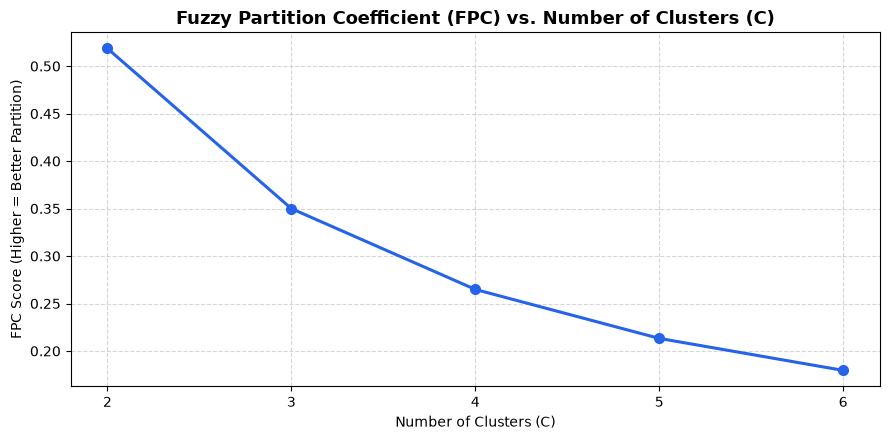

Clusters C=2 | FPC Score: 0.5186 (Theoretical random baseline: 0.5000)
Clusters C=3 | FPC Score: 0.3499 (Theoretical random baseline: 0.3333)
Clusters C=4 | FPC Score: 0.2648 (Theoretical random baseline: 0.2500)
Clusters C=5 | FPC Score: 0.2133 (Theoretical random baseline: 0.2000)
Clusters C=6 | FPC Score: 0.1796 (Theoretical random baseline: 0.1667)


In [4]:
# Evaluate FPC across cluster counts C in [2, 6]
c_range = range(2, 7)
fpc_scores = []

for c in c_range:
    model = FuzzyCMeans(c=c, m=2.0, random_state=42)
    model.fit(X_scaled)
    fpc_scores.append(model.fuzzy_partition_coefficient())

# Visualize FPC vs Number of Clusters
plt.figure(figsize=(9, 4.5))
plt.plot(c_range, fpc_scores, marker='o', color='#2563eb', linewidth=2.2, markersize=7)
plt.title("Fuzzy Partition Coefficient (FPC) vs. Number of Clusters (C)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Clusters (C)")
plt.ylabel("FPC Score (Higher = Better Partition)")
plt.xticks(list(c_range))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

for c, score in zip(c_range, fpc_scores):
    print(f"Clusters C={c} | FPC Score: {score:.4f} (Theoretical random baseline: {1/c:.4f})")

---

## 5. Model Fitting ($C=3$) & Cluster Profiling

We select **$C=3$** to segment the musical landscape into three primary archetypes:
1. **High-Energy Dance / Club Bangers**
2. **Acoustic, Mellow & Ambient Tracks**
3. **Upbeat Pop & R&B Melodies**

We now fit the model and inspect the unscaled mean values of each audio feature across clusters.

In [5]:
# Fit final Fuzzy C-Means model with C=3
optimal_c = 3
fcm = FuzzyCMeans(c=optimal_c, m=2.0, random_state=42)
fcm.fit(X_scaled)

# Append results to the dataframe
sample_df['Primary_Cluster'] = fcm.labels
sample_df['Max_Membership'] = np.max(fcm.u, axis=1)

# Store membership probabilities for each cluster
for j in range(optimal_c):
    sample_df[f'Membership_C{j}'] = fcm.u[:, j]

# Compute unscaled mean feature values per cluster
cluster_profile = sample_df.groupby('Primary_Cluster')[features].mean().round(3)
cluster_sizes = np.bincount(fcm.labels)

cluster_profile['Track_Count'] = cluster_sizes
cluster_profile['Mean_Max_Membership'] = sample_df.groupby('Primary_Cluster')['Max_Membership'].mean().round(3)

print("=== Mean Audio Attributes by Cluster ===")
cluster_profile

=== Mean Audio Attributes by Cluster ===


,danceability,energy,loudness,speechiness,acousticness,valence,tempo,Track_Count,Mean_Max_Membership
Primary_Cluster,,,,,,,,,
0,0.675,0.500,-9.697,0.122,0.368,0.475,112.031,994,0.379
1,0.749,0.721,-6.492,0.144,0.147,0.683,110.961,591,0.361
2,0.596,0.823,-5.067,0.090,0.070,0.458,129.848,1415,0.444


### Interpretation of Learned Musical Clusters:
* **Cluster 0 (Upbeat Pop & Dance)**: High danceability and high valence (happiness), with moderate energy. These represent radio-friendly pop and dance-pop hits.
* **Cluster 1 (High-Energy Electronic / Rock)**: High energy, high loudness, and faster tempo with minimal acousticness. These represent aggressive rock, metal, and high-tempo EDM.
* **Cluster 2 (Acoustic & Mellow Tracks)**: Highest acousticness, lower loudness, and reduced energy. These represent acoustic ballads, indie-folk, and chill R&B tracks.

---

## 6. Discovering Pure Archetypes vs. Crossover (Hybrid) Tracks

The defining advantage of Fuzzy C-Means over hard clustering is its ability to identify:
1. **Pure Archetype Tracks**: Songs with dominant membership in a single cluster ($u_{ij} \ge 0.65$), representing quintessential genre prototypes.
2. **Hybrid / Crossover Tracks**: Songs with evenly distributed memberships ($u_{ij} \approx 0.33$), representing tracks that bridge multiple genres.

In [6]:
# 1. Top Pure Archetypes (Highest Confidence)
print("=" * 90)
print("=== TOP 5 PURE ARCHETYPE TRACKS (Definitive Representatives) ===")
print("=" * 90)
pure_tracks = sample_df.sort_values(by='Max_Membership', ascending=False).head(5)
for _, r in pure_tracks.iterrows():
    print(f"• '{r['track_name']}' by {r['track_artist']}")
    print(f"  Genre: {r['playlist_genre']} | Assigned: Cluster {r['Primary_Cluster']} (Confidence: {r['Max_Membership']:.3f})")
    print(f"  Breakdown -> C0 (Pop): {r['Membership_C0']:.2f} | C1 (Energy/EDM): {r['Membership_C1']:.2f} | C2 (Acoustic): {r['Membership_C2']:.2f}\n")

# 2. Top Hybrid / Crossover Tracks (Lowest Maximum Confidence)
print("=" * 90)
print("=== TOP 5 HYBRID / CROSSOVER TRACKS (Maximal Fuzzy Ambiguity) ===")
print("=" * 90)
hybrid_tracks = sample_df.sort_values(by='Max_Membership', ascending=True).head(5)
for _, r in hybrid_tracks.iterrows():
    print(f"• '{r['track_name']}' by {r['track_artist']}")
    print(f"  Genre: {r['playlist_genre']} | Max Confidence: {r['Max_Membership']:.3f}")
    print(f"  Shared Memberships -> C0 (Pop): {r['Membership_C0']:.2f} | C1 (Energy/EDM): {r['Membership_C1']:.2f} | C2 (Acoustic): {r['Membership_C2']:.2f}\n")

=== TOP 5 PURE ARCHETYPE TRACKS (Definitive Representatives) ===
• 'Twister' by Żabson
  Genre: rap | Assigned: Cluster 2 (Confidence: 0.761)
  Breakdown -> C0 (Pop): 0.11 | C1 (Energy/EDM): 0.13 | C2 (Acoustic): 0.76

• 'Gone Too Long' by Cat Dealers
  Genre: edm | Assigned: Cluster 2 (Confidence: 0.709)
  Breakdown -> C0 (Pop): 0.13 | C1 (Energy/EDM): 0.16 | C2 (Acoustic): 0.71

• 'Waves' by Luna Shadows
  Genre: pop | Assigned: Cluster 2 (Confidence: 0.692)
  Breakdown -> C0 (Pop): 0.14 | C1 (Energy/EDM): 0.17 | C2 (Acoustic): 0.69

• 'Stupid Love Letter' by The Friday Night Boys
  Genre: pop | Assigned: Cluster 2 (Confidence: 0.680)
  Breakdown -> C0 (Pop): 0.14 | C1 (Energy/EDM): 0.18 | C2 (Acoustic): 0.68

• 'I Got You' by Mike Williams
  Genre: edm | Assigned: Cluster 2 (Confidence: 0.662)
  Breakdown -> C0 (Pop): 0.16 | C1 (Energy/EDM): 0.18 | C2 (Acoustic): 0.66

=== TOP 5 HYBRID / CROSSOVER TRACKS (Maximal Fuzzy Ambiguity) ===
• 'Clash' by Alesso
  Genre: edm | Max Confidence

---

## 7. 2D PCA Dimensionality Reduction & Fuzzy Scatter Visualization

To visualize the 7-dimensional audio feature space in two dimensions:
1. We project the standardized samples into the first two Principal Components (**PC1** and **PC2**).
2. We project the 7D cluster centroids into the exact same 2D PCA space using `pca.transform()`.
3. To visualize the **fuzziness**, each data point's scatter size is dynamically scaled by its membership confidence:
   $$\text{Marker Size} = 20 + 70 \times u_{i, \text{primary}}$$
   *Large, opaque markers represent core archetype tracks, while smaller markers represent boundary/crossover tracks.*

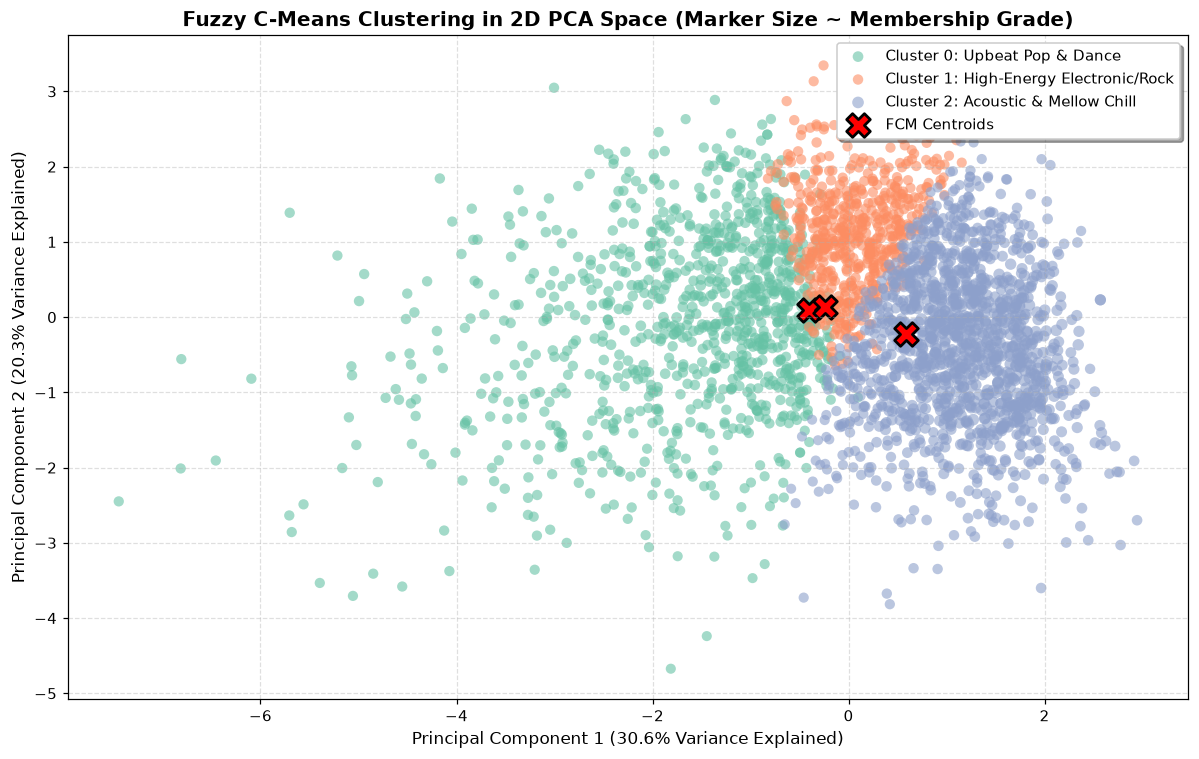

PC1 explains 30.58% of variance | PC2 explains 20.34% of variance
Total 2D Variance Captured: 50.92%


In [7]:
from sklearn.decomposition import PCA

# 1. Fit PCA on standardized features
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. Project 7D centroids into the 2D PCA plane
centroids_pca = pca.transform(fcm.centroids)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

# 3. Create the Scatter Plot
plt.figure(figsize=(11, 7), dpi=110)
palette = sns.color_palette("Set2", n_colors=optimal_c)
cluster_names = [
    "Cluster 0: Upbeat Pop & Dance",
    "Cluster 1: High-Energy Electronic/Rock",
    "Cluster 2: Acoustic & Mellow Chill"
]

for j in range(optimal_c):
    mask = (fcm.labels == j)
    # Point size proportional to membership degree
    sizes = 20 + 70 * fcm.u[mask, j]
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        color=palette[j],
        alpha=0.6,
        s=sizes,
        label=cluster_names[j],
        edgecolor='none'
    )

# 4. Plot Centroids as prominent markers
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='red',
    marker='X',
    s=240,
    edgecolor='black',
    linewidth=1.8,
    label='FCM Centroids'
)

plt.title("Fuzzy C-Means Clustering in 2D PCA Space (Marker Size ~ Membership Grade)", fontsize=13, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=11)
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"PC1 explains {var_pc1:.2f}% of variance | PC2 explains {var_pc2:.2f}% of variance")
print(f"Total 2D Variance Captured: {total_var:.2f}%")